# NAC-ViT Classification Results

Visualizations for the unfrozen ViT-B/16 runs. The numbers below are the accuracies that were measured.

- Pooled test (330 images): **96.36%** (318/330). Macro F1 **0.964**. Macro AUC **0.998**.
- Pooled validation at the saved checkpoint (epoch 9): **97.85%**.
- Archive Testing folder (394 images): **78.43%** (309/394). Macro F1 **0.750**. Macro AUC **0.924**.
- Frozen backbone, previously reported and not remeasured here: **69.05%**.

Run this notebook from the `NAC-ViT` project directory. The inference cell loads `runs/classify/nac_vit_pooled/best.pt` and scores the saved test split. Figures are written to `runs/classify/nac_vit_pooled/figures/`.


## 1. Setup


In [28]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from train_nac_vit import IMAGENET_MEAN, IMAGENET_STD, json_to_rows, load_model, make_transforms

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "train_nac_vit.py").is_file():
    raise FileNotFoundError("Run this notebook from the NAC-ViT project directory.")

POOLED_DIR = PROJECT_DIR / "runs" / "classify" / "nac_vit_pooled"
OFFICIAL_DIR = PROJECT_DIR / "runs" / "classify" / "nac_vit"
FIG_DIR = POOLED_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_LABELS = {
    "glioma": "Glioma",
    "meningioma": "Meningioma",
    "no_tumor": "No Tumor",
    "pituitary": "Pituitary",
}
CLASS_COLORS = {
    "glioma": "#4C78A8",
    "meningioma": "#F58518",
    "no_tumor": "#54A24B",
    "pituitary": "#E45756",
}
# Published frozen-backbone baseline from the project report.
FROZEN = {
    "accuracy": 0.6905,
    "macro_f1": 0.68,
    "macro_auc": 0.884,
    "per_class_f1": {
        "glioma": 0.73,
        "meningioma": 0.59,
        "no_tumor": 0.80,
        "pituitary": 0.79,
    },
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})


def save_figure(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_DIR)}")
    plt.show()


def pretty(name):
    return CLASS_LABELS.get(name, name.replace("_", " ").title())


#print(f"Project: {PROJECT_DIR}")
#print(f"Figures: {FIG_DIR}")


## 2. Load the run


In [16]:
history = pd.read_csv(POOLED_DIR / "history.csv")
pooled = json.loads((POOLED_DIR / "results.json").read_text())
official = json.loads((OFFICIAL_DIR / "results.json").read_text())
splits = json.loads((POOLED_DIR / "splits.json").read_text())
class_names = [row["class"] for row in pooled["test"]["per_class"]]
best_row = history.loc[history["val_accuracy"].idxmax()]
best_epoch = int(best_row["epoch"])

print(f"Epochs ran: {int(history['epoch'].iloc[-1])} of 40 (early stopping)")
print(f"Best validation epoch: {best_epoch}  accuracy {best_row['val_accuracy']:.2%}")
print(f"Pooled test accuracy: {pooled['test']['accuracy']:.2%}")
print(f"Official Testing-folder accuracy: {official['test']['accuracy']:.2%}")
print()
print(history.round(4).to_string(index=False))


Epochs ran: 17 of 40 (early stopping)
Best validation epoch: 9  accuracy 97.85%
Pooled test accuracy: 96.36%
Official Testing-folder accuracy: 78.43%

 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1  lr_backbone  lr_head
     1      0.7956          0.7589    0.3888        0.8769        0.8811          0.0   0.0000
     2      0.5695          0.9011    0.2752        0.9169        0.9169          0.0   0.0001
     3      0.4739          0.9521    0.2090        0.9538        0.9568          0.0   0.0001
     4      0.4202          0.9716    0.2285        0.9569        0.9596          0.0   0.0001
     5      0.4030          0.9797    0.1742        0.9600        0.9611          0.0   0.0001
     6      0.3775          0.9889    0.1692        0.9692        0.9729          0.0   0.0001
     7      0.3672          0.9939    0.1889        0.9600        0.9647          0.0   0.0001
     8      0.3709          0.9920    0.1570        0.9692        0.9728          0.0   0

## 3. Headline metrics


In [17]:
summary = pd.DataFrame([
    {
        "Protocol": "Frozen backbone (published)",
        "Accuracy": FROZEN["accuracy"],
        "Macro F1": FROZEN["macro_f1"],
        "AUC": FROZEN["macro_auc"],
    },
    {
        "Protocol": "Unfrozen, official Testing folder",
        "Accuracy": official["test"]["accuracy"],
        "Macro F1": official["test"]["macro_f1"],
        "AUC": official["test"]["macro_auc"],
    },
    {
        "Protocol": "Unfrozen, pooled validation",
        "Accuracy": pooled["val"]["accuracy"],
        "Macro F1": pooled["val"]["macro_f1"],
        "AUC": pooled["val"]["macro_auc"],
    },
    {
        "Protocol": "Unfrozen, pooled test",
        "Accuracy": pooled["test"]["accuracy"],
        "Macro F1": pooled["test"]["macro_f1"],
        "AUC": pooled["test"]["macro_auc"],
    },
])
shown = summary.copy()
for column in ["Accuracy", "Macro F1", "AUC"]:
    shown[column] = shown[column].map(lambda value: f"{value:.4f}")
print(shown.to_string(index=False))


                         Protocol Accuracy Macro F1    AUC
      Frozen backbone (published)   0.6905   0.6800 0.8840
Unfrozen, official Testing folder   0.7843   0.7501 0.9243
      Unfrozen, pooled validation   0.9785   0.9810 0.9917
            Unfrozen, pooled test   0.9636   0.9635 0.9983


## 4. Training curves

Loss, accuracy, validation F1, and the two learning rates. The vertical line is the checkpoint epoch, chosen by validation accuracy.


saved runs/classify/nac_vit_pooled/figures/training_curves.png


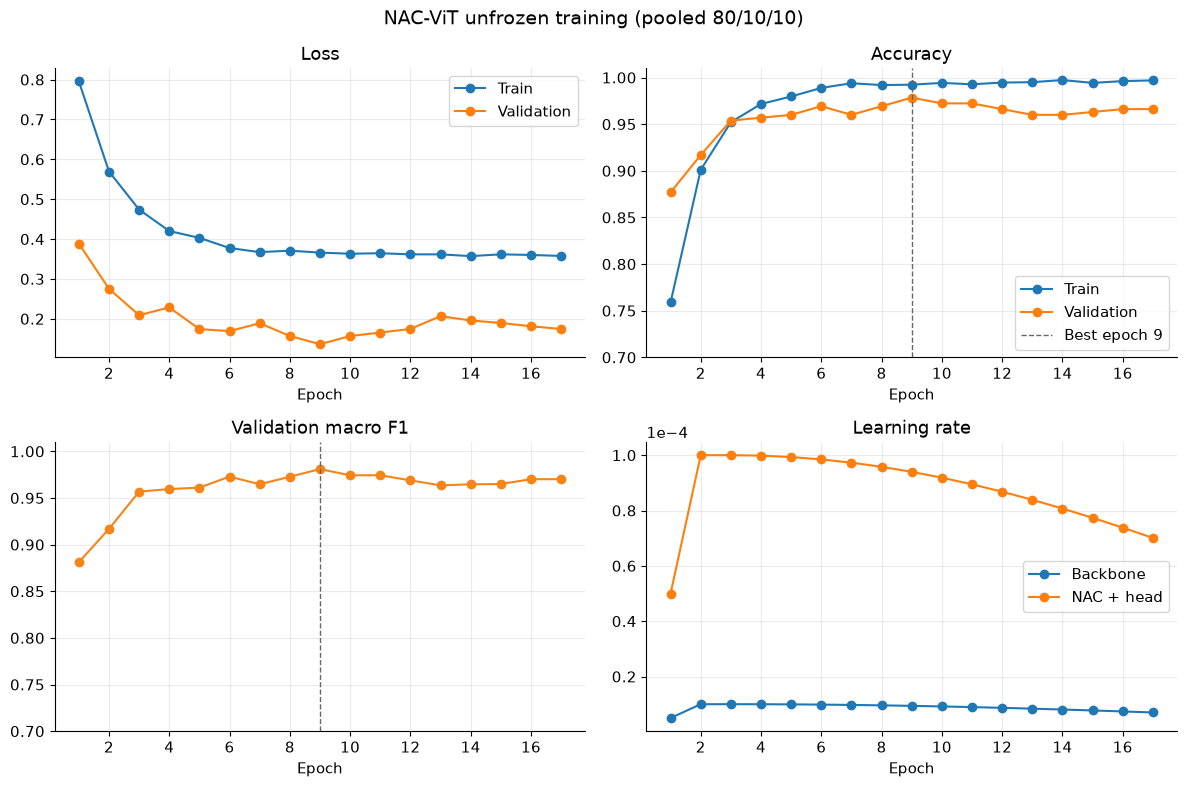

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(history["epoch"], history["train_loss"], marker="o", label="Train")
axes[0, 0].plot(history["epoch"], history["val_loss"], marker="o", label="Validation")
axes[0, 0].set_title("Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].legend()

axes[0, 1].plot(history["epoch"], history["train_accuracy"], marker="o", label="Train")
axes[0, 1].plot(history["epoch"], history["val_accuracy"], marker="o", label="Validation")
axes[0, 1].axvline(best_epoch, color="0.4", ls="--", lw=1, label=f"Best epoch {best_epoch}")

axes[0, 1].set_ylim(0.7, 1.01)
axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].legend()

axes[1, 0].plot(history["epoch"], history["val_macro_f1"], marker="o", color="#F58518")
axes[1, 0].axvline(best_epoch, color="0.4", ls="--", lw=1)
axes[1, 0].set_ylim(0.7, 1.01)
axes[1, 0].set_title("Validation macro F1")
axes[1, 0].set_xlabel("Epoch")

axes[1, 1].plot(history["epoch"], history["lr_backbone"], marker="o", label="Backbone")
axes[1, 1].plot(history["epoch"], history["lr_head"], marker="o", label="NAC + head")
axes[1, 1].set_title("Learning rate")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1, 1].legend()

fig.suptitle("NAC-ViT unfrozen training (pooled 80/10/10)", fontsize=14)
fig.tight_layout()
save_figure(fig, "training_curves.png")


## 5. Dataset split


       glioma  meningioma  no_tumor  pituitary  total
split                                                
train     740         749       400        720   2609
val        92          93        50         90    325
test       94          95        50         91    330
saved runs/classify/nac_vit_pooled/figures/split_balance.png


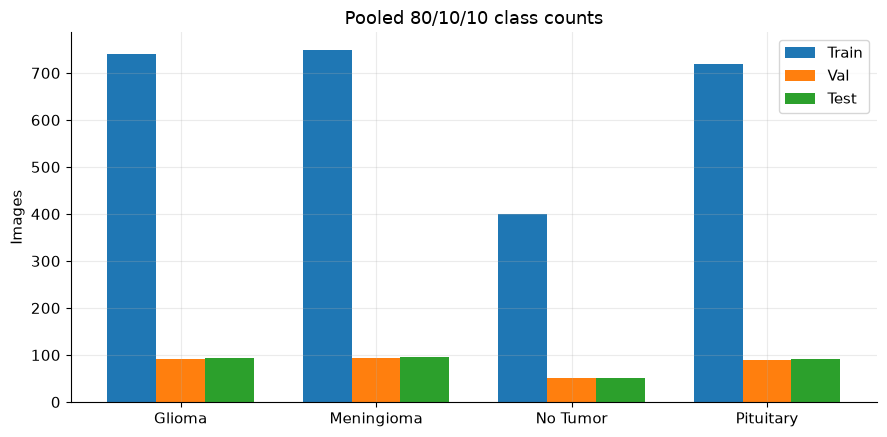

In [19]:
rows = []
for split_name, records in splits.items():
    counts = {name: 0 for name in class_names}
    for record in records:
        counts[record["label"]] += 1
    counts["split"] = split_name
    counts["total"] = len(records)
    rows.append(counts)

balance = pd.DataFrame(rows).set_index("split").loc[["train", "val", "test"]]
print(balance.to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(class_names))
width = 0.25
for offset, split_name in enumerate(["train", "val", "test"]):
    values = [int(balance.loc[split_name, name]) for name in class_names]
    ax.bar(x + (offset - 1) * width, values, width, label=split_name.capitalize())
ax.set_xticks(x, [pretty(name) for name in class_names])
ax.set_ylabel("Images")
ax.set_title("Pooled 80/10/10 class counts")
ax.legend()
fig.tight_layout()
save_figure(fig, "split_balance.png")


## 6. Per-class test metrics


     class  precision  recall     f1    auc  support
    glioma     0.9670  0.9362 0.9514 0.9952       94
meningioma     0.9490  0.9789 0.9637 0.9987       95
  no_tumor     0.9259  1.0000 0.9615 0.9997       50
 pituitary     1.0000  0.9560 0.9775 0.9995       91


saved runs/classify/nac_vit_pooled/figures/per_class_metrics.png


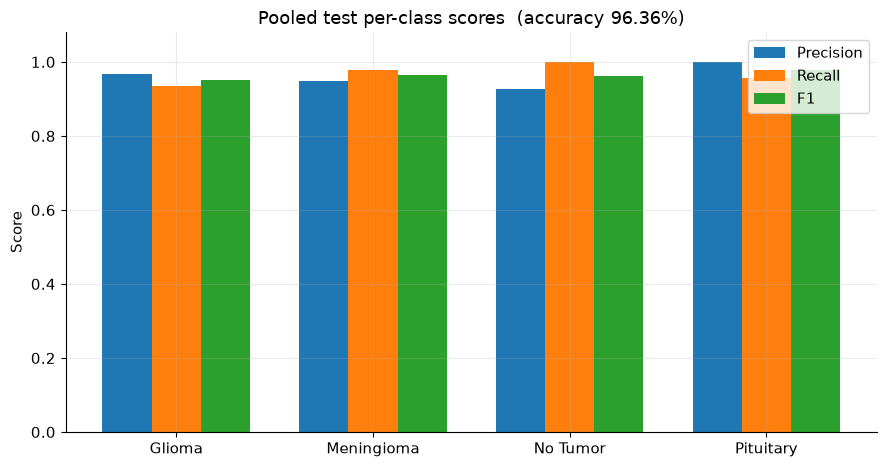

saved runs/classify/nac_vit_pooled/figures/per_class_auc.png


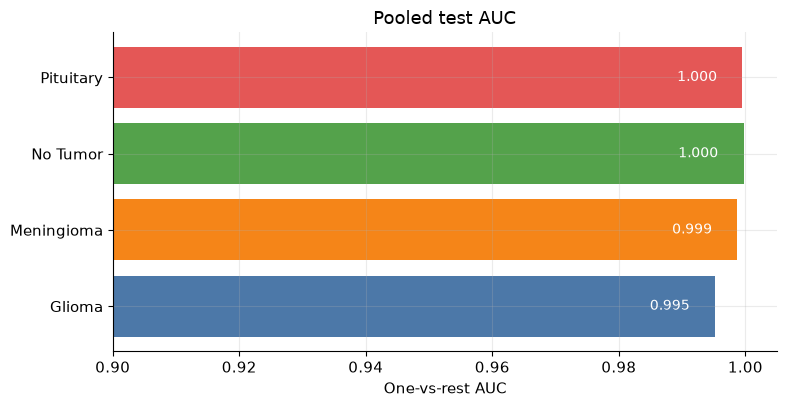

In [20]:
per_class = pd.DataFrame(pooled["test"]["per_class"])
print(per_class.round(4).to_string(index=False))

metrics = ["precision", "recall", "f1"]
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(per_class))
width = 0.25
for offset, metric in enumerate(metrics):
    ax.bar(x + (offset - 1) * width, per_class[metric], width, label=metric.capitalize())
ax.set_xticks(x, [pretty(name) for name in per_class["class"]])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title(f"Pooled test per-class scores  (accuracy {pooled['test']['accuracy']:.2%})")
ax.legend()
fig.tight_layout()
save_figure(fig, "per_class_metrics.png")

fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [CLASS_COLORS[name] for name in per_class["class"]]
bars = ax.barh([pretty(name) for name in per_class["class"]], per_class["auc"], color=colors)
ax.set_xlim(0.9, 1.005)
ax.set_xlabel("One-vs-rest AUC")
ax.set_title("Pooled test AUC")
for bar, value in zip(bars, per_class["auc"]):
    ax.text(value - 0.004, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", ha="right", color="white", fontsize=10)
fig.tight_layout()
save_figure(fig, "per_class_auc.png")


## 7. Protocol comparison

Each bar is an accuracy that was measured or previously reported. The frozen run trained only the NAC blocks and the head (69.05%). The official run keeps the dataset Testing folder as the test set (78.43%). The pooled run mixes every image, then holds out 10% (96.36%).


saved runs/classify/nac_vit_pooled/figures/protocol_comparison.png


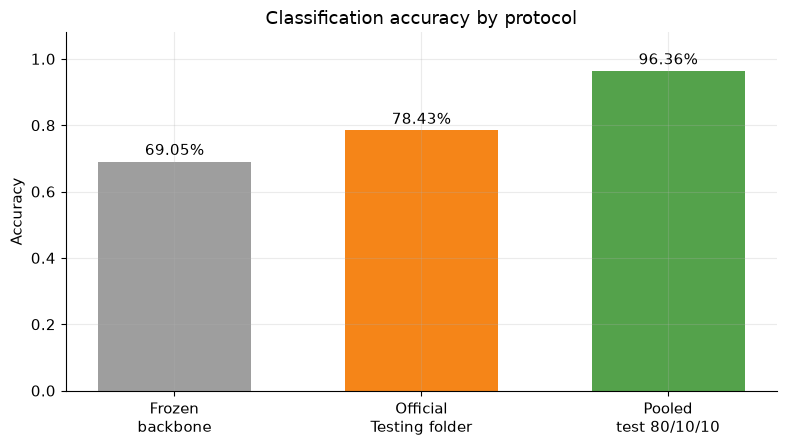

saved runs/classify/nac_vit_pooled/figures/per_class_f1_comparison.png


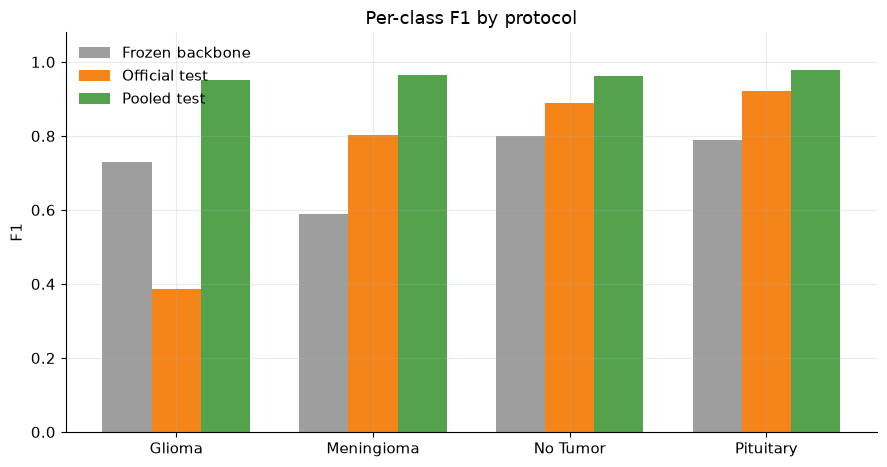

In [21]:
protocols = ["Frozen\nbackbone", "Official\nTesting folder", "Pooled\ntest 80/10/10"]
accuracies = [FROZEN["accuracy"], official["test"]["accuracy"], pooled["test"]["accuracy"]]
colors = ["#9e9e9e", "#F58518", "#54A24B"]

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(protocols, accuracies, color=colors, width=0.62)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Accuracy")
ax.set_title("Classification accuracy by protocol")
for bar, value in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.2%}", ha="center", fontsize=11)
fig.tight_layout()
save_figure(fig, "protocol_comparison.png")

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(class_names))
width = 0.25
series = [
    ("Frozen backbone", [FROZEN["per_class_f1"][name] for name in class_names], "#9e9e9e"),
    ("Official test", [next(row["f1"] for row in official["test"]["per_class"] if row["class"] == name) for name in class_names], "#F58518"),
    ("Pooled test", [next(row["f1"] for row in pooled["test"]["per_class"] if row["class"] == name) for name in class_names], "#54A24B"),
]
for offset, (label, values, color) in enumerate(series):
    ax.bar(x + (offset - 1) * width, values, width, label=label, color=color)
ax.set_xticks(x, [pretty(name) for name in class_names])
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1")
ax.set_title("Per-class F1 by protocol")
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "per_class_f1_comparison.png")


## 8. Test-set predictions

The next cell loads the pooled checkpoint and scores the 330 saved test images. Later cells use `labels`, `predictions`, `probabilities`, and `images`.


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
model, checkpoint = load_model(POOLED_DIR / "best.pt", device)
model.eval()
_, eval_transform = make_transforms(checkpoint["imgsz"])
test_rows = json_to_rows(splits["test"])
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

labels, predictions, probabilities, images = [], [], [], []
with torch.inference_mode():
    for start in range(0, len(test_rows), 16):
        batch = test_rows[start:start + 16]
        tensors, batch_labels = [], []
        for path, label in batch:
            with Image.open(path) as image:
                tensors.append(eval_transform(image.convert("RGB")))
            batch_labels.append(class_names.index(label))
        batch_tensor = torch.stack(tensors).to(device)
        probability = torch.softmax(model(batch_tensor), dim=1).cpu()
        labels.extend(batch_labels)
        predictions.extend(probability.argmax(dim=1).tolist())
        probabilities.extend(probability.tolist())
        images.extend((tensor.cpu() * std + mean).clamp(0, 1) for tensor in tensors)

labels = np.asarray(labels)
predictions = np.asarray(predictions)
probabilities = np.asarray(probabilities)
accuracy = float((labels == predictions).mean())
print(f"Scored {len(labels)} test images")
print(f"Accuracy from this pass: {accuracy:.2%}")
del model
if device.type == "cuda":
    torch.cuda.empty_cache()


Device: cuda


Scored 330 test images
Accuracy from this pass: 96.36%


## 9. Confusion matrix


saved runs/classify/nac_vit_pooled/figures/confusion_matrix.png


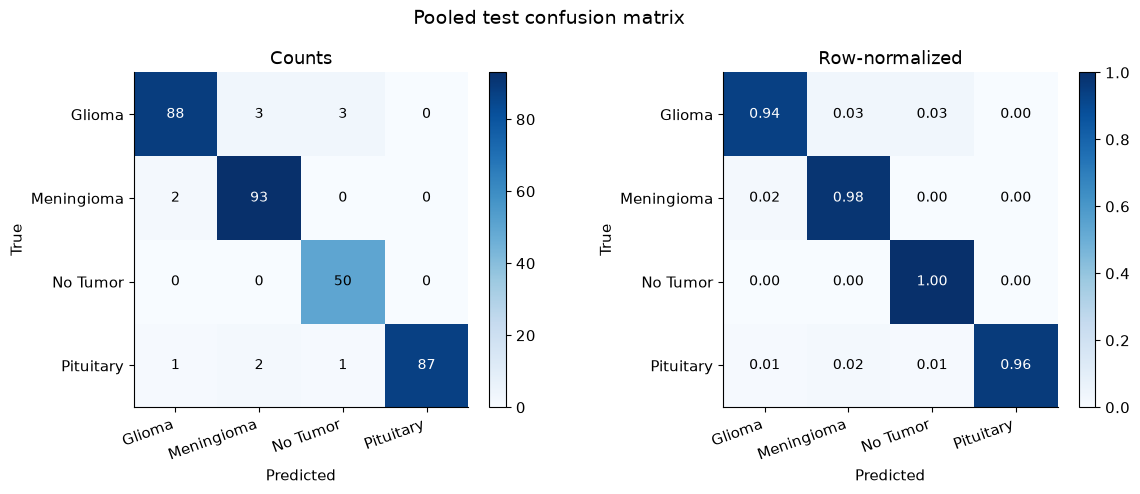

In [23]:
n_classes = len(class_names)
matrix = np.zeros((n_classes, n_classes), dtype=int)
for truth, guess in zip(labels, predictions):
    matrix[truth, guess] += 1
normalized = matrix / matrix.sum(axis=1, keepdims=True).clip(min=1)
tick_labels = [pretty(name) for name in class_names]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, values, title, fmt in [
    (axes[0], matrix, "Counts", "{:.0f}"),
    (axes[1], normalized, "Row-normalized", "{:.2f}"),
]:
    image = ax.imshow(values, cmap="Blues", vmin=0, vmax=values.max())
    ax.set_xticks(range(n_classes), tick_labels, rotation=20, ha="right")
    ax.set_yticks(range(n_classes), tick_labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    ax.grid(False)
    for row in range(n_classes):
        for col in range(n_classes):
            tone = "white" if values[row, col] > values.max() * 0.55 else "black"
            ax.text(col, row, fmt.format(values[row, col]), ha="center", va="center", color=tone, fontsize=10)
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.suptitle("Pooled test confusion matrix", fontsize=14)
fig.tight_layout()
save_figure(fig, "confusion_matrix.png")


## 10. ROC curves


saved runs/classify/nac_vit_pooled/figures/roc_curves.png


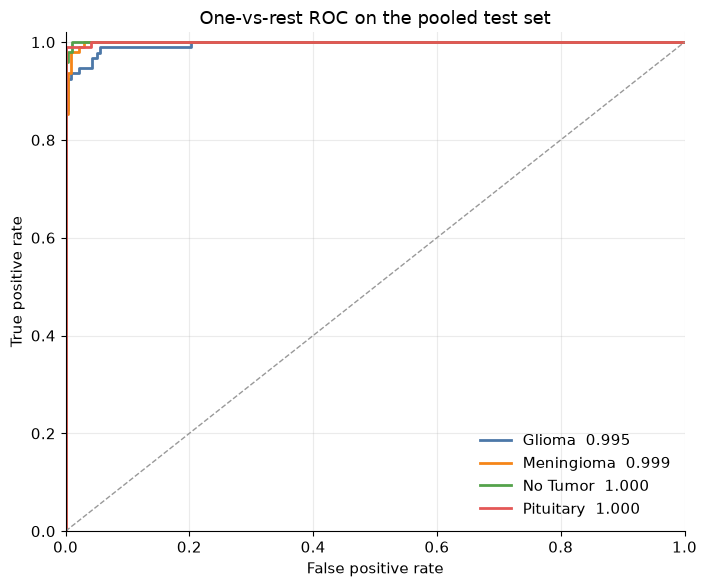

In [24]:
def roc_curve(binary_labels, scores):
    order = np.argsort(-scores)
    ordered = binary_labels[order]
    tps = np.cumsum(ordered == 1)
    fps = np.cumsum(ordered == 0)
    n_pos = max(int((binary_labels == 1).sum()), 1)
    n_neg = max(int((binary_labels == 0).sum()), 1)
    tpr = np.concatenate([[0.0], tps / n_pos])
    fpr = np.concatenate([[0.0], fps / n_neg])
    auc = float(np.trapezoid(tpr, fpr))
    return fpr, tpr, auc


fig, ax = plt.subplots(figsize=(7.2, 6))
for index, name in enumerate(class_names):
    binary = (labels == index).astype(int)
    fpr, tpr, auc = roc_curve(binary, probabilities[:, index])
    ax.plot(fpr, tpr, color=CLASS_COLORS[name], lw=2, label=f"{pretty(name)}  {auc:.3f}")
ax.plot([0, 1], [0, 1], color="0.6", ls="--", lw=1)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("One-vs-rest ROC on the pooled test set")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save_figure(fig, "roc_curves.png")


## 11. Prediction confidence


saved runs/classify/nac_vit_pooled/figures/confidence_histogram.png


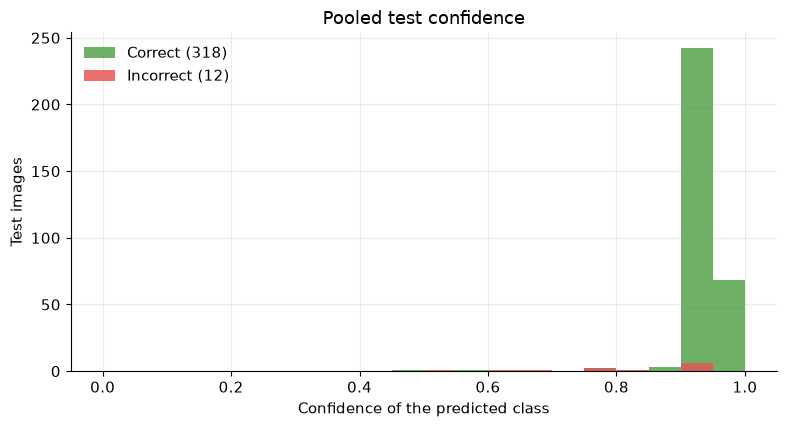

In [25]:
confidence = probabilities[np.arange(len(predictions)), predictions]
correct = labels == predictions
fig, ax = plt.subplots(figsize=(8, 4.4))
bins = np.linspace(0, 1, 21)
ax.hist(confidence[correct], bins=bins, alpha=0.85, label=f"Correct ({correct.sum()})", color="#54A24B")
ax.hist(confidence[~correct], bins=bins, alpha=0.85, label=f"Incorrect ({(~correct).sum()})", color="#E45756")
ax.set_xlabel("Confidence of the predicted class")
ax.set_ylabel("Test images")
ax.set_title("Pooled test confidence")
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "confidence_histogram.png")


## 12. Example predictions


Misclassified test images: 12 of 330


saved runs/classify/nac_vit_pooled/figures/misclassified_examples.png


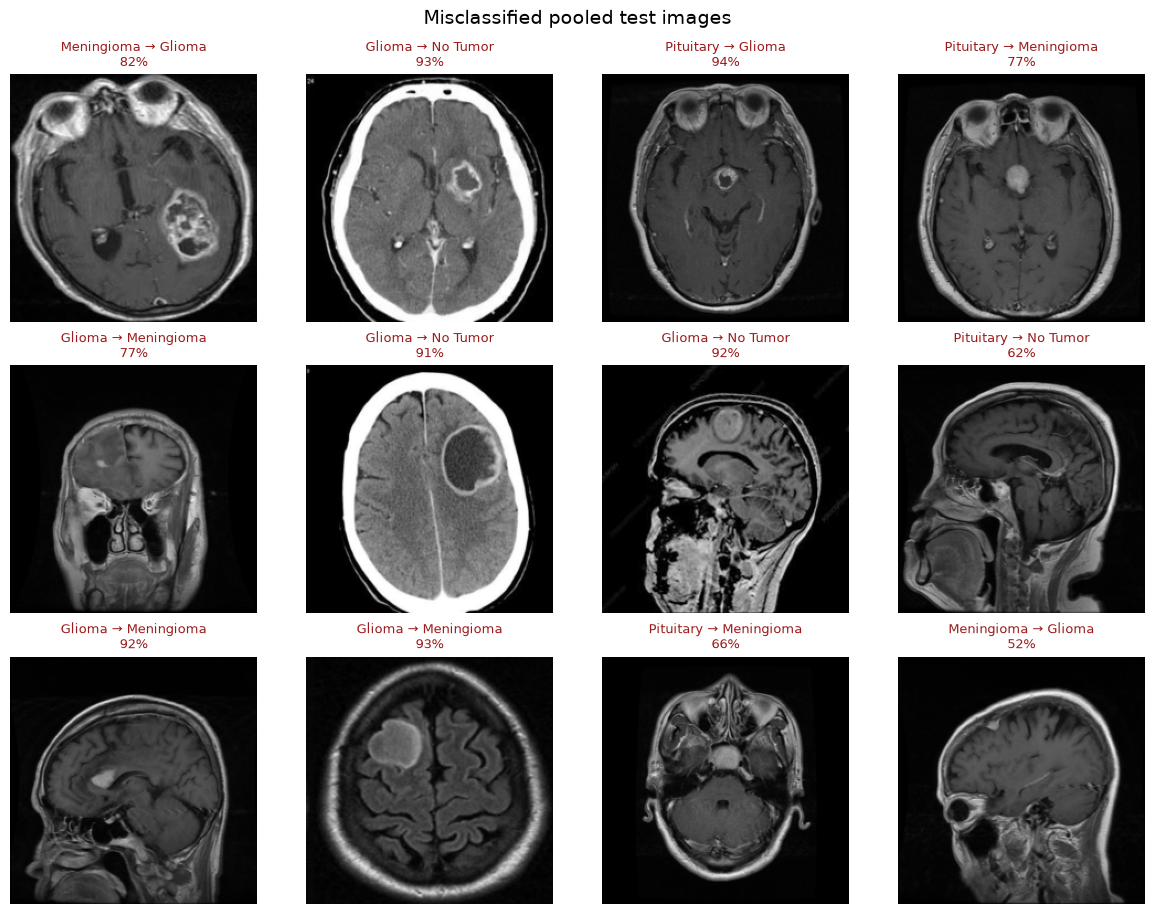

saved runs/classify/nac_vit_pooled/figures/correct_examples.png


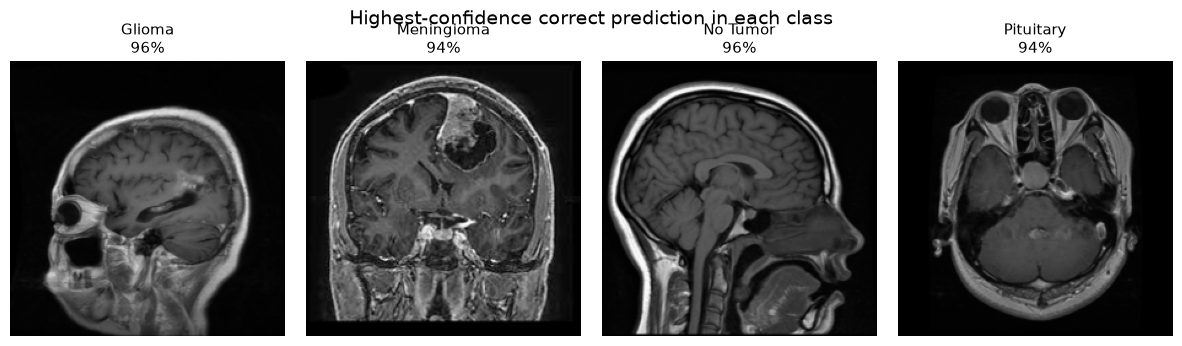

In [26]:
mistakes = np.flatnonzero(labels != predictions)
print(f"Misclassified test images: {len(mistakes)} of {len(labels)}")

def panel_title(index):
    truth = pretty(class_names[labels[index]])
    guess = pretty(class_names[predictions[index]])
    conf = probabilities[index, predictions[index]]
    return f"{truth} → {guess}\n{conf:.0%}"


cols = 4
rows = int(np.ceil(len(mistakes) / cols)) if len(mistakes) else 1
fig, axes = plt.subplots(rows, cols, figsize=(12, 3.1 * rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes:
    ax.axis("off")
    ax.grid(False)
if len(mistakes) == 0:
    axes[0].set_title("No misclassified test images")
else:
    for ax, index in zip(axes, mistakes):
        ax.imshow(images[index].permute(1, 2, 0).numpy())
        ax.set_title(panel_title(index), fontsize=9, color="#9B1C1C")
fig.suptitle("Misclassified pooled test images", fontsize=14)
fig.tight_layout()
save_figure(fig, "misclassified_examples.png")

fig, axes = plt.subplots(1, len(class_names), figsize=(12, 3.5))
for ax, name in zip(axes, class_names):
    class_index = class_names.index(name)
    candidates = np.flatnonzero((labels == class_index) & (predictions == class_index))
    ax.axis("off")
    ax.grid(False)
    if len(candidates) == 0:
        ax.set_title(pretty(name))
        continue
    best = candidates[np.argmax(probabilities[candidates, class_index])]
    ax.imshow(images[best].permute(1, 2, 0).numpy())
    ax.set_title(f"{pretty(name)}\n{probabilities[best, class_index]:.0%}", fontsize=11)
fig.suptitle("Highest-confidence correct prediction in each class", fontsize=14)
fig.tight_layout()
save_figure(fig, "correct_examples.png")


## 13. NAC dynamics

Each NAC block has four attention heads. φ is the logistic gate, ω is the leak, and τ = 1/ω. These values are the learned parameters stored in the checkpoint.


saved runs/classify/nac_vit_pooled/figures/nac_dynamics.png


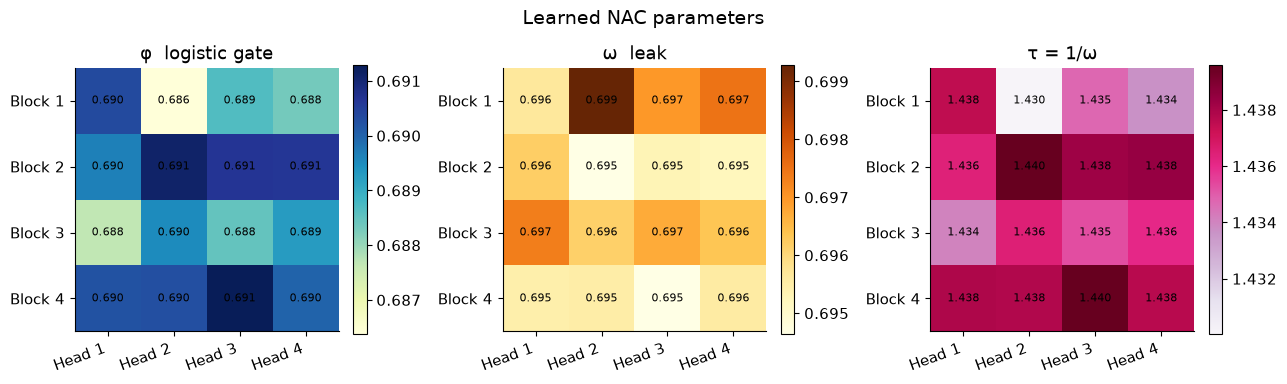

Figures written to runs/classify/nac_vit_pooled/figures


In [27]:
dynamics = checkpoint["nac_dynamics"]
phi = np.array([block["phi"] for block in dynamics])
omega = np.array([block["omega"] for block in dynamics])
tau = np.array([block["tau"] for block in dynamics])
heads = [f"Head {i + 1}" for i in range(phi.shape[1])]
blocks = [f"Block {i + 1}" for i in range(phi.shape[0])]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, values, title, cmap in [
    (axes[0], phi, "φ  logistic gate", "YlGnBu"),
    (axes[1], omega, "ω  leak", "YlOrBr"),
    (axes[2], tau, "τ = 1/ω", "PuRd"),
]:
    image = ax.imshow(values, cmap=cmap)
    ax.set_xticks(range(len(heads)), heads, rotation=20, ha="right")
    ax.set_yticks(range(len(blocks)), blocks)
    ax.set_title(title)
    ax.grid(False)
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            ax.text(col, row, f"{values[row, col]:.3f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.suptitle("Learned NAC parameters", fontsize=14)
fig.tight_layout()
save_figure(fig, "nac_dynamics.png")
print("Figures written to", FIG_DIR.relative_to(PROJECT_DIR))
